# Stratified performance: does C2 beat MSP where C0's classes overlap?

**Question.** Over all rows, the best C2 model barely beats threshold-MSP. The hypothesis is that
its advantage is concentrated where C0's positive and negative probability distributions
overlap: at those p, C0 is right about as often as it is wrong, so p (and therefore MSP) carries
no information about correctness, and anything C2 ranks correctly there must come from
somewhere else.

**Models compared** (all at K = 10, nothing retrained here):

| name | what it is | why it is here |
|---|---|---|
| MSP | threshold-MSP from C0's probability | the baseline to beat |
| I | attribute MLP on the query only, no counterfactual | the *honest* comparator (see below) |
| ens | the K=10 ensemble (`MLP_I+C+D` + `dual_sal` CNN) | our best C2 model |

The ensemble's combiner (mean / rank / lr) is the one with the best mean-fold AUROC on **all**
rows, so nothing is tuned on the region.

**Layout.** Section 1 is the analysis. The appendix keeps the older views (risk-coverage and
C0-probability quintiles), which answer related but different questions.

In [34]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from sklearn.metrics import roc_curve
from sklearn.metrics import roc_auc_score
import sys
sys.path.insert(0, os.path.abspath("code"))
from c2_msp import MSP_VARIANTS, msp_score

# Which MSP every figure uses as the baseline
MSP_VARIANT = "threshold"

# K = number of counterfactual neighbours the attributes are pooled over. Every model
# here is the final system, at FINAL["k"].
K_VALUES = [1, 5, 10]

# The final system (Aims 2 and 3): each family's ablation winner at one K. Section 1f of
# C2_evaluation.ipynb tested adding C0's probability (I+C+D+P, dual_sal_scalars) and it did not
# help, so the final system is probability-free. "prob": True would switch every Aim 2 figure,
# test and table to the probability models (attributes_prob/, ensemble_prob/).
FINAL = {"k": 10, "attr": "I+C+D", "cnn": "dual_sal", "prob": False}
FINAL_ATTR_SUB = "attributes_prob" if FINAL["prob"] else "attributes"
FINAL_ENS_SUB  = "ensemble_prob"   if FINAL["prob"] else "ensemble"
# Copied from C2_evaluation.ipynb -- keep the two in sync.

RESULTS = os.environ.get("THESIS_RESULTS", "/work3/s251710/thesis_results")
C2      = os.path.join(RESULTS, "C2_final_results")
SOURCE, POLICY = "knn_correct_cf", "ignore"
DISEASES = ["effusion", "atelectasis", "cardiomegaly", "consolidation", "edema"]
CNN_KEYS = ["xi", "xi_sal", "cf", "cf_sal", "dual", "dual_sal", "dual_sal_scalars"]
# Same idea as CONFIG_GROUPS: fixed order, with a rule separating the models that see a
# single image from those that see the query/counterfactual pair.
CNN_GROUPS = [["xi", "xi_sal", "cf", "cf_sal"], ["dual", "dual_sal", "dual_sal_scalars"]]
# The image models that never see a counterfactual. Shaded in the CNN ladder, and the
# reason their K lines coincide: with no CF input there is nothing for K to vary.
CNN_NO_CF = ["xi", "xi_sal"]
# Tick labels in the attribute notation, so CNN and attribute figures read side by side:
# I = query image, C = counterfactual image, Sal = saliency maps. Keys stay the model names.
CNN_LABELS = {"xi": "I", "xi_sal": "I+Sal", "cf": "C", "cf_sal": "C+Sal",
              "dual": "I+C", "dual_sal": "I+C+Sal", "dual_sal_scalars": "I+C+Sal+P"}

# Canonical config order -- NOT sorted by performance, so a config sits in the same
# row in every panel and the eye can track it across diseases. Single blocks | combinations.
CONFIG_GROUPS = [["I", "C", "D"], ["I+C", "I+C+D"]]
CONFIG_ORDER = [c for g in CONFIG_GROUPS for c in g]
# The nested families bootstrapping.ipynb tests: I -> I+C -> I+C+D.
ATTR_FAMILIES = {"I": ["I"], "I+C": ["I+C"], "I+C+D": ["I+C+D"]}

# Thesis-wide style: colour = model family (attributes blue, CNN red, ensemble purple,
# trajectory green, MSP light grey dashed); lightness = how much counterfactual a model sees (tint = none,
# darker = more, so K=1 -> 10 runs light -> dark). Sizes are print sizes: FULL / HALF are the
# Nature column widths and MM converts millimetres. See code/thesis_style.py.
import importlib, thesis_style
importlib.reload(thesis_style)     # pick up edits to the style file without a kernel restart
from thesis_style import *
apply()
BLUE, RED = FAMILY["attr"], FAMILY["cnn"]
K_COLOR    = k_colors("attr", K_VALUES)


# Every figure is also written to FIG_DIR, ready to upload to Overleaf as one folder. Both
# C2 notebooks write to the SAME folder and are told apart by FIG_PREFIX. PDF is vector (use
# it in \includegraphics); PNG is a 600-dpi raster copy (savefig.dpi in thesis_style).
FIG_DIR     = os.path.join("figures", "c2")
FIG_PREFIX  = "knn"
FIG_FORMATS = ("pdf", "png")


def save_fig(fig, name):
    """Write `fig` as FIG_DIR/<FIG_PREFIX>_<name>.<ext>. No-op for None (nothing drawn yet)."""
    if fig is None:
        return
    os.makedirs(FIG_DIR, exist_ok=True)
    for ext in FIG_FORMATS:
        fig.savefig(os.path.join(FIG_DIR, f"{FIG_PREFIX}_{name}.{ext}"))


## Loaders

In [35]:
def attr_dir(d, k=None, sub="attributes"): return os.path.join(C2, d, SOURCE, f"cf_{k or FINAL['k']}", sub)
def cnn_dir(d, key, k=None): return os.path.join(C2, d, SOURCE, f"cf_{k or FINAL['k']}", "images", key)

def load_attributes(disease, k=None, n_folds=5, sub="attributes"):
    """Pooled out-of-fold attribute predictions for one K; `fold` kept so per-fold
    means stay available. Returns None if that K has not finished, so a partially
    run K sweep still renders."""
    parts = []
    for i in range(n_folds):
        p = os.path.join(attr_dir(disease, k, sub), f"fold_{i}_predictions.csv")
        if not os.path.exists(p):
            return None
        f = pd.read_csv(p); f["fold"] = i
        parts.append(f)
    return pd.concat(parts, ignore_index=True)

def load_cnn(disease, k=None, n_folds=5):
    """Pooled OOF CNN predictions, one column per FINISHED model (fold_aucs.csv present),
    so the notebook works mid-run.

    Columns are renamed `cnn_<key>`: the `cf` model writes `cf_prob`, which collides with
    the attribute frame's own `cf_prob` (mean counterfactual C0 probability) on merge.
    """
    out = None
    for key in CNN_KEYS:
        if not os.path.exists(os.path.join(cnn_dir(disease, key, k), "fold_aucs.csv")):
            continue
        parts = []
        for i in range(n_folds):
            p = os.path.join(cnn_dir(disease, key, k), f"fold_{i}_predictions.csv")
            if not os.path.exists(p): break
            f = pd.read_csv(p); f["fold"] = i
            parts.append(f)
        else:
            df = (pd.concat(parts, ignore_index=True)
                    [["path","patient_id","correct","fold",f"{key}_prob"]]
                    .rename(columns={f"{key}_prob": f"cnn_{key}"}))
            out = df if out is None else out.merge(df[["path", f"cnn_{key}"]], on="path", how="outer")
    return out

def msp(df, disease, variant=None):
    """Maximum softmax probability -- the untrained baseline. Nothing is fitted.
    `variant` defaults to MSP_VARIANT; the threshold is only read when a variant needs it."""
    variant = variant or MSP_VARIANT
    p = df[f"{disease}_prob"].values
    t = None if variant == "standard" else c0_threshold(disease)
    return msp_score(p, t, variant)

def config_cols(df, model="MLP"):
    """Config -> column, in CONFIG_ORDER. Configs absent from the file are skipped."""
    have = {c.split("_",1)[1].rsplit("_prob",1)[0]: c
            for c in df.columns if c.startswith(f"{model}_") and c.endswith("_prob")}
    return {c: have[c] for c in CONFIG_ORDER if c in have}

def c0_threshold(disease, policy=POLICY):
    p = os.path.join(RESULTS, "C0_final", f"multilabel_{policy}", disease, "threshold.txt")
    return float(open(p).read().strip())

def panel_note(df, disease, policy=POLICY):
    """Per-panel subtitle: sample count and C0's error profile.

    n is NOT comparable across diseases by accident -- uncertain (-1) CheXpert labels have
    no defined C0 correctness and are dropped, and each disease loses a different number of
    them, so every panel is a different-sized set.

    FP/FN split C0's errors by the class it predicted. Neither `pred` nor `true` is stored
    in the fold predictions, but both are recoverable: pred = prob >= threshold, and since
    `correct` is exactly (pred == true), a wrong row has true = 1 - pred. So an error with
    pred=1 is a false positive and an error with pred=0 is a false negative. Percentages are
    of all rows, so FP% + FN% = the C0 error rate.
    """
    corr = df["correct"].values.astype(int)
    pred = (df[f"{disease}_prob"].values >= c0_threshold(disease, policy)).astype(int)
    n = len(df)
    fp = ((pred == 1) & (corr == 0)).sum() / n
    fn = ((pred == 0) & (corr == 0)).sum() / n
    return f"n={n:,}  ·  C0 err {1 - corr.mean():.1%}  (FP {fp:.1%} / FN {fn:.1%})"

def titled(ax, disease, df):
    ax.set_title(disease, pad=11)
    ax.text(0.0, 1.02, panel_note(df, disease), transform=ax.transAxes,
            ha="left", va="bottom", fontsize=FS["tiny"], color=MUTED)

def per_fold_auc(df, score_col_or_values):
    """Mean AUROC over the 5 folds -- the same statistic cv_summary.csv reports."""
    v = df[score_col_or_values] if isinstance(score_col_or_values, str) else pd.Series(
        score_col_or_values, index=df.index)
    return float(np.mean([roc_auc_score(g["correct"], v.loc[g.index])
                          for _, g in df.groupby("fold")]))

## Metrics

In [36]:
def risk_coverage(correct, score, min_n=200):
    """Retain the most-confident-first prefix. risk(c) = C0 error rate among the retained.

    `min_n` trims the left tail: at coverage ~0 the risk is an average over a handful of
    samples and swings between 0 and 1, which is sampling noise, not signal. AURC below
    still integrates the full curve -- only the plot is trimmed.
    """
    order = np.argsort(-np.asarray(score, float))
    y = np.asarray(correct, int)[order]
    k = np.arange(1, len(y) + 1)
    cov, risk = k / len(y), np.cumsum(1 - y) / k
    return cov[min_n - 1:], risk[min_n - 1:]

def aurc(correct, score):
    return risk_coverage(correct, score, min_n=1)[1].mean()

def e_aurc(correct, score):
    """Excess AURC: AURC minus that of a perfect ranking. Removes the base error rate,
    which spans 19-40% across these diseases and would otherwise dominate any comparison."""
    return aurc(correct, score) - aurc(correct, np.asarray(correct, float))

def errors_caught(correct, score, budget=0.20):
    """Flag the `budget` least-confident share; return the share of C0's errors caught."""
    y = np.asarray(correct, int)
    flagged = np.argsort(np.asarray(score, float))[:int(round(budget * len(y)))]
    n_err = (y == 0).sum()
    return (y[flagged] == 0).sum() / n_err if n_err else np.nan

## Best-model selection

Copied from `C2_evaluation.ipynb` (with `FINAL`) (`_grid` from Aim 1, `best_attr` / `best_cnn` / `best_ens` from
2a, `load_ensemble` / `best_ensemble` from 2b) without their figures.

In [37]:
def _grid(n, ncols, panel=(4.0, 4.6)):
    """Axes grid with the unused trailing cells removed.

    Cells are taller than wide even though the axes are square: the extra height is
    what the x labels, and the title lines consume,
    so the square plot sits in the cell without a wide margin.
    """
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(panel[0] * ncols, panel[1] * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes[n:]:
        ax.remove()
    return fig, axes[:n]


def best_attr(disease, model="MLP", ks=None):
    """The final system's attribute model, FINAL["attr"] at FINAL["k"] (in FINAL_ATTR_SUB).

    Returns (config, K, score vector, frame, auroc), the same shape the search it replaces
    returned, so every caller is unchanged. `ks` is accepted and ignored: nothing is searched.
    """
    k  = FINAL["k"]
    df = load_attributes(disease, k, sub=FINAL_ATTR_SUB)
    if df is None:
        return None
    col = f"{model}_{FINAL['attr']}_prob"
    return (FINAL["attr"], k, df[col], df, per_fold_auc(df, col))


def best_cnn(disease, ks=None):
    """The final system's CNN, FINAL["cnn"] at FINAL["k"].
    Returns (variant, K, frame, column, auroc). `ks` is ignored."""
    k, key = FINAL["k"], FINAL["cnn"]
    cnn = load_cnn(disease, k)
    col = f"cnn_{key}"
    if cnn is None or col not in cnn.columns or not cnn[col].notna().all():
        return None
    return (key, k, cnn, col, per_fold_auc(cnn, col))


def best_ens(disease, ks=None):
    """The final ensemble (FINAL_ENS_SUB at FINAL["k"]) with its best combiner, by mean
    fold AUROC -- the same pick as the bootstrap's `best_ens`.
    Returns (combiner, K, frame, column, auroc); the frame carries the C0 probability
    so MSP can be scored on exactly the ensemble's rows. `ks` is ignored."""
    ref, best, k = load_attributes(disease, FINAL["k"]), None, FINAL["k"]
    if ref is None:
        return None
    p = os.path.join(C2, disease, SOURCE, f"cf_{k}", FINAL_ENS_SUB, "oof_predictions.csv")
    if not os.path.exists(p):
        return None
    m = pd.read_csv(p).merge(ref[["path", f"{disease}_prob"]], on="path", how="inner")
    for col in [x for x in m.columns if x.startswith("ens_")]:
        a = per_fold_auc(m, col)
        if best is None or a > best[-1]:
            best = (col[len("ens_"):], k, m, col, a)
    return best


def load_ensemble(disease, k):
    """`ensemble_summary.csv` for one disease and K, or None if that run is absent.

    Written by c2_ensemble.py; nothing is fitted here.
    """
    p = os.path.join(C2, disease, SOURCE, f"cf_{k}", FINAL_ENS_SUB, "ensemble_summary.csv")
    if not os.path.exists(p):
        return None
    df   = pd.read_csv(p)
    comp = df[df["kind"] == "component"].set_index("members")["auc_mean"]
    ens  = df[df["kind"] == "ensemble"].set_index("method")
    if comp.empty or ens.empty:
        return None
    # members is "<model>_prob"; only the attribute one carries an estimator prefix.
    attr = next((m for m in comp.index if m.split("_")[0] in ("MLP", "LR", "RF")), None)
    cnn  = next((m for m in comp.index if m != attr), None)
    if attr is None or cnn is None:
        return None
    return {"k": k, "attr": (attr[:-5], float(comp[attr])),
            "cnn": (cnn[:-5], float(comp[cnn])), "ens": ens}


def best_ensemble(disease, ks=None):
    """The final ensemble, at FINAL["k"]. Nothing is searched: the members and K are FINAL,
    fixed before looking at the ensemble, so a lucky combiner cannot pick the row. `ks` is ignored."""
    return load_ensemble(disease, FINAL["k"])

# 1 - C2 vs MSP inside the overlap region

**Defining the region.** For every row we estimate `P(C0 correct | p)`. Above the threshold t this
equals `P(y=1 | p)`, below it `P(y=0 | p)`, so `P(correct | p) ≈ 0.5` is exactly where the two
classes are equally common at that p: the class overlap. A row is **in the region at δ** when
`|P(correct | p) − 0.5| < δ`.

`P(correct | p)` is fitted with isotonic regression, separately on each side of t (on each side
correctness is monotone in the distance from t). It is cross-fitted: each fold's rows are scored
by a fit on the other four, so no row chooses its own membership.

**Reading the result.** Inside the region MSP is squeezed into a narrow range, so its AUROC sits
near 0.5 almost by construction; beating MSP there is close to automatic. The counterfactual claim
needs **ens > I** as well: `I` sees the query embedding, which already contains C0's logit, but no
counterfactual. If ens beats MSP but not I, the gain is not coming from counterfactuals.

**Statistics.** AUROC is computed per fold and averaged (each fold is a separate model, so scores
are only comparable within a fold). Confidence intervals are a paired bootstrap over patients,
resampled within each fold and inside the region; all three models are scored on the same draw.

In [65]:
from scipy.stats import rankdata
from sklearn.isotonic import IsotonicRegression

K_MAIN     = 10                                  # K the ensemble and I are read at
DELTAS     = [0.01, 0.05, 0.10, 0.15, 0.20]     # half-widths of |P(correct | p) - 0.5| < δ
DELTA_MAIN = 0.05                                # the one the figures shade and the table reports
MIN_CLASS  = 10       # a fold is scored only if its region holds >= this many correct AND wrong rows
N_BOOT     = 1000
MODELS     = ["MSP", "I", "ens"]
OV_COLOR   = {"MSP": GREY, "I": RAMP["attr"][0], "ens": ENS}   # I = no CF -> lightest attribute blue


def overlap_frame(disease, k=K_MAIN):
    """Rows = images; columns = C0 prob, fold, patient, correct. Returns (df, scores, labels).

    Attribute and ensemble predictions are joined on path; their fold assignments must agree,
    otherwise a per-fold AUROC would mix models.
    """
    attr = load_attributes(disease, k)
    ens_dir = os.path.join(C2, disease, SOURCE, f"cf_{k}", "ensemble")
    summ = pd.read_csv(os.path.join(ens_dir, "ensemble_summary.csv"))
    summ = summ[summ["kind"] == "ensemble"]
    method  = summ.loc[summ["auc_mean"].idxmax(), "method"]      # chosen on ALL rows
    members = summ["members"].iloc[0].replace("_prob", "")
    oof = pd.read_csv(os.path.join(ens_dir, "oof_predictions.csv"))

    df = (attr[["path", "patient_id", "fold", "correct", f"{disease}_prob", "MLP_I_prob"]]
          .merge(oof[["path", "fold", f"ens_{method}"]], on="path", how="inner",
                 suffixes=("", "_ens")))
    assert (df["fold"] == df["fold_ens"]).all(), f"{disease}: attribute and ensemble folds disagree"
    if len(df) != len(attr):
        print(f"{disease}: {len(attr) - len(df):,} attribute rows have no ensemble prediction")
    df = df.drop(columns="fold_ens").reset_index(drop=True)

    scores = {"MSP": msp(df, disease),
              "I":   df["MLP_I_prob"].values,
              "ens": df[f"ens_{method}"].values}
    labels = {"MSP": f"MSP ({MSP_VARIANT})", "I": "I (no CF)",
              "ens": f"ens {method} ({members})"}
    return df, scores, labels


def p_correct(df, disease):
    """Cross-fitted P(C0 correct | p), one isotonic fit per side of the threshold."""
    p, t = df[f"{disease}_prob"].values, c0_threshold(disease)
    y, fold = df["correct"].values, df["fold"].values
    out = np.empty(len(df))
    for f in np.unique(fold):
        te, tr = fold == f, fold != f
        for side, inc in ((p < t, False), (p >= t, True)):
            iso = IsotonicRegression(increasing=inc, out_of_bounds="clip")
            iso.fit(p[tr & side], y[tr & side])
            out[te & side] = iso.predict(p[te & side])
    return out


def fast_auc(y, s):
    """AUROC via ranks (ties averaged, same as roc_auc_score). NaN if either class < MIN_CLASS."""
    y = np.asarray(y, bool)
    n1 = int(y.sum()); n0 = len(y) - n1
    if min(n1, n0) < MIN_CLASS:
        return np.nan
    r = rankdata(s)
    return (r[y].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)


def region_auc(df, s, mask):
    """Per-fold AUROC of score `s` on the rows in `mask`."""
    y, fold = df["correct"].values, df["fold"].values
    return np.array([fast_auc(y[mask & (fold == f)], s[mask & (fold == f)])
                     for f in np.unique(fold)])


def boot_region_auc(df, scores, mask, n_boot=N_BOOT, seed=0):
    """(n_boot, len(MODELS)) mean-fold AUROCs on patient-bootstrap draws of the region.

    Patients are resampled within each fold (a fold keeps its own model) and every model is
    scored on the same draw, so differences between columns are paired.
    """
    rng = np.random.default_rng(seed)
    y, fold, pid = df["correct"].values, df["fold"].values, df["patient_id"].values
    S = np.column_stack([scores[m] for m in MODELS])
    folds = []
    for f in np.unique(fold):
        idx = np.flatnonzero(mask & (fold == f))
        codes, uniq = pd.factorize(pid[idx])
        order = np.argsort(codes, kind="stable")
        idx = idx[order]
        lens = np.bincount(codes, minlength=len(uniq))
        starts = np.concatenate([[0], np.cumsum(lens)[:-1]])
        folds.append((idx, starts, lens))
    out = np.empty((n_boot, len(MODELS)))
    for b in range(n_boot):
        per_fold = []
        for idx, starts, lens in folds:
            g = rng.integers(len(lens), size=len(lens))          # patients drawn with replacement
            L = lens[g]
            offs = np.arange(L.sum()) - np.repeat(np.cumsum(L) - L, L)
            i = idx[np.repeat(starts[g], L) + offs]
            per_fold.append([fast_auc(y[i], S[i, j]) for j in range(len(MODELS))])
        out[b] = np.nanmean(np.array(per_fold, float), axis=0)
    return out


def errors_caught_in(df, s, mask):
    """Per fold, flag as many region rows as it has C0 errors (least confident by `s`) and
    count the real errors among them. Returns (errors in region, errors caught), summed over folds."""
    y, fold = df["correct"].values, df["fold"].values
    n_err = n_hit = 0
    for f in np.unique(fold):
        m = mask & (fold == f)
        e = int((y[m] == 0).sum())
        n_err += e
        n_hit += int((y[m][np.argsort(s[m], kind="stable")[:e]] == 0).sum())
    return n_err, n_hit


def build_overlap(disease):
    df, scores, labels = overlap_frame(disease)
    df["pc"] = p_correct(df, disease)
    everything = np.ones(len(df), bool)
    auc = {(m, d): region_auc(df, scores[m], everything if d is None else (df.pc - 0.5).abs().values < d)
           for m in MODELS for d in DELTAS + [None]}
    main = (df.pc - 0.5).abs().values < DELTA_MAIN
    return {"df": df, "scores": scores, "labels": labels, "auc": auc,
            "boot": boot_region_auc(df, scores, main)}


OVERLAP = {d: build_overlap(d) for d in DISEASES}

/tmp/ipykernel_2160511/3897864024.py:101: RuntimeWarning: Mean of empty slice
  out[b] = np.nanmean(np.array(per_fold, float), axis=0)


## 1a. Where C0's classes overlap

C0's probability p for the truly **negative** (filled) and truly **positive** (outline) images.
Where one class clearly dominates, p already tells you whether C0 is right, and MSP is hard to
beat. The **shaded band** is where the two are about equally common (`|P(y=1 | p) − 0.5| < δ`):
there, p says nothing about correctness, so this is where C2 has to add something.

Read the subtitle as: how big the band is and how many of C0's errors live in it. A tiny band
(atelectasis, consolidation) means C0 rarely finds itself in a real coin-flip region, so there is
little room for C2 to win there regardless of how good it is.

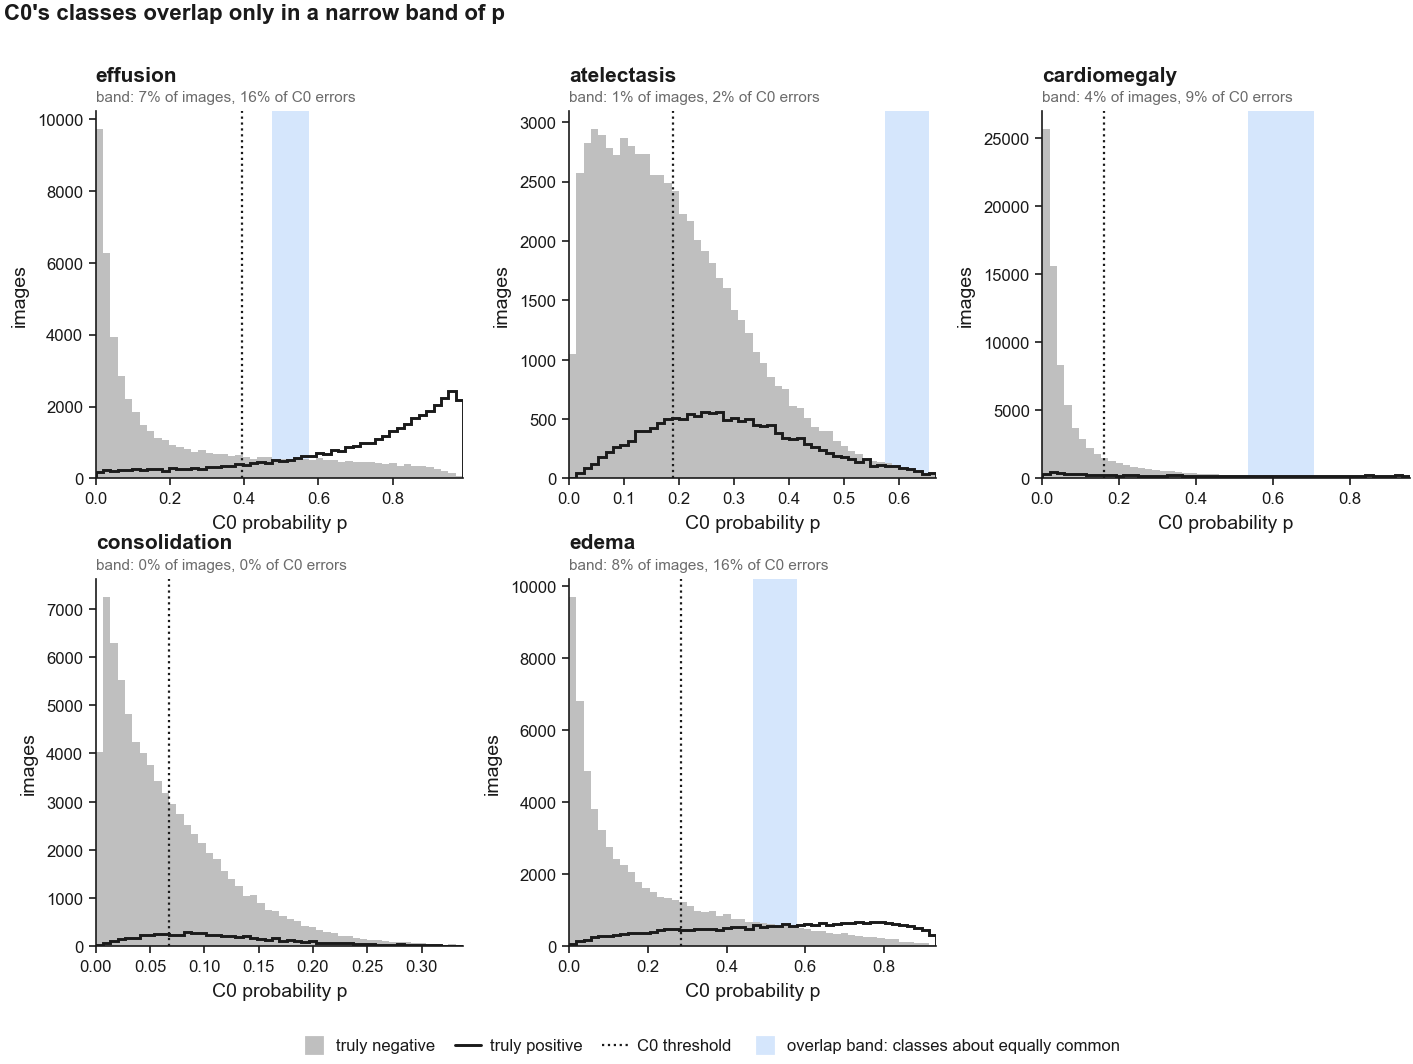

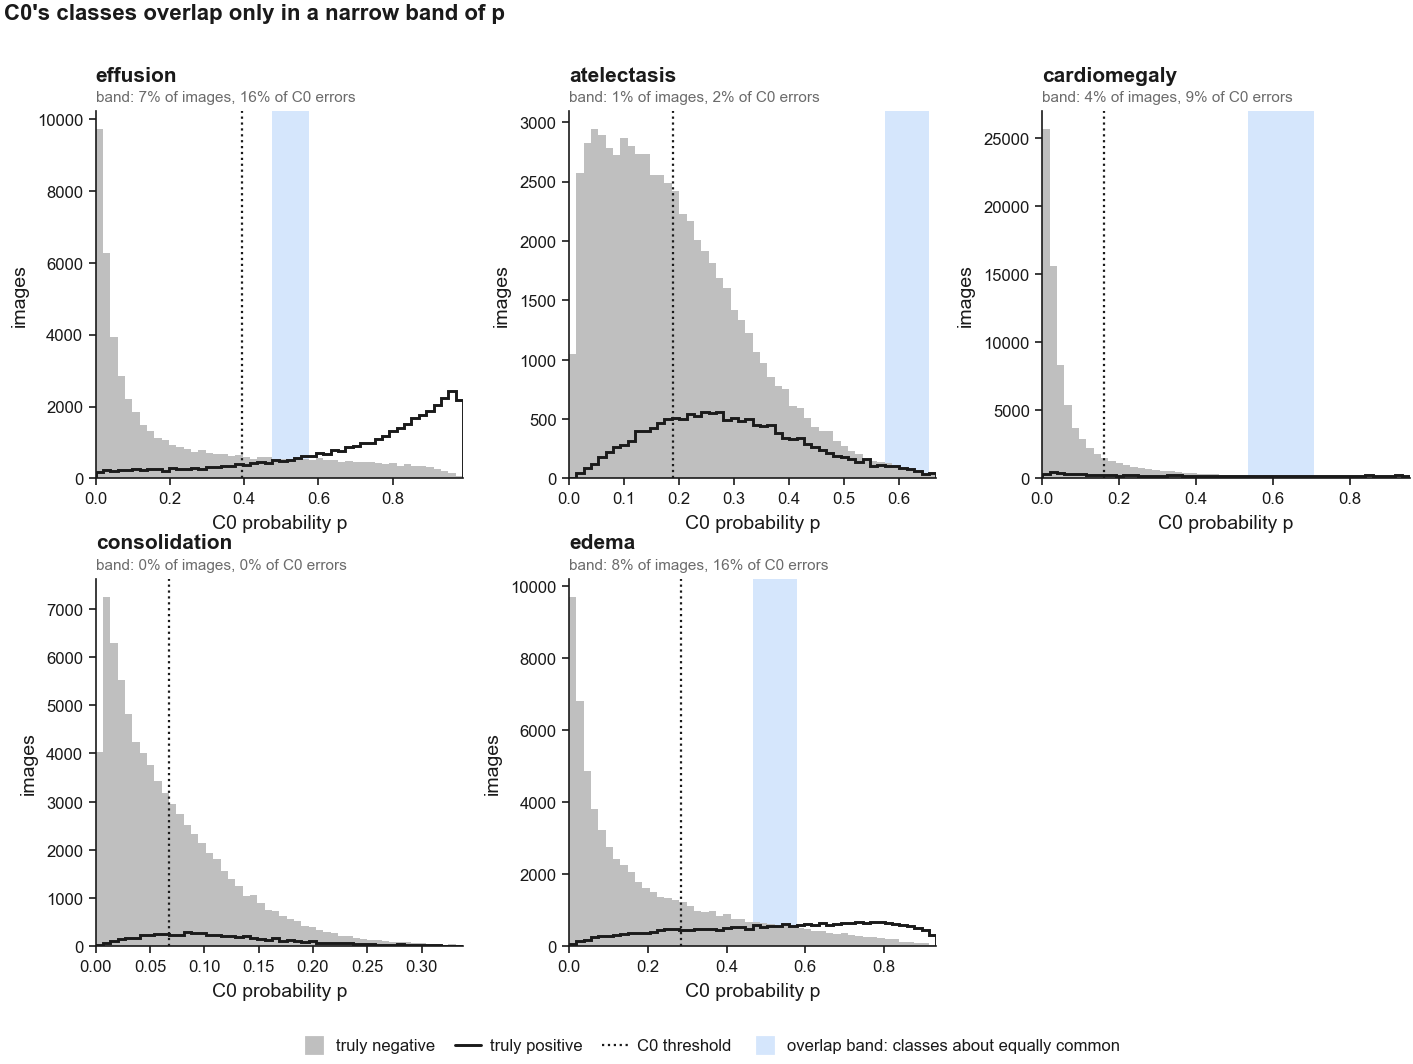

In [66]:
def logit(p):
    p = np.clip(np.asarray(p, float), 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))


def true_label(df, disease):
    """y is not stored, but pred = p >= t and correct = (pred == y), so y = pred if correct else 1 - pred."""
    pred = (df[f"{disease}_prob"].values >= c0_threshold(disease)).astype(int)
    return np.where(df["correct"].values == 1, pred, 1 - pred)




def overlap_panel(ax, disease, delta=DELTA_MAIN, bins=50):
    df = OVERLAP[disease]["df"]
    x, t = df[f"{disease}_prob"].values, c0_threshold(disease)
    y = true_label(df, disease)
    # Plain probability axis. The right edge stops at the 99.5th percentile so a disease whose
    # p never gets near 1 (consolidation tops out around 0.3) doesn't waste most of the panel.
    edges = np.linspace(0, np.percentile(x, 99.5), bins + 1)
    inside = ((df.pc - 0.5).abs() < delta).values

    # Shade a bin when most of its images are in the region (P(y=1 | p) is a step function,
    # so a bin is almost always all in or all out).
    idx = np.clip(np.digitize(x, edges) - 1, 0, bins - 1)
    for i in range(bins):
        m = idx == i
        if m.any() and inside[m].mean() > 0.5:
            ax.axvspan(edges[i], edges[i + 1], color=TINT["attr"], lw=0, zorder=0)
    ax.hist(x[y == 0], edges, color=GREY, lw=0, zorder=1)
    ax.hist(x[y == 1], edges, histtype="step", color=INK, lw=LW["line"] * 0.7, zorder=2)
    ax.axvline(t, color=INK, ls=":", lw=LW["ref"], zorder=3)

    ax.set_xlim(edges[0], edges[-1])
    ax.set_xlabel("C0 probability p"); ax.set_ylabel("images")
    ax.set_box_aspect(1)
    ax.set_title(disease, pad=11)
    err = df["correct"].values == 0
    ax.text(0.0, 1.02, f"band: {inside.mean():.0%} of images, {(inside & err).sum() / err.sum():.0%} of C0 errors",
            transform=ax.transAxes, ha="left", va="bottom", fontsize=FS["tiny"], color=MUTED)


fig, axes = _grid(len(DISEASES), 3, panel=(FULL / 3, 66 * MM))
for ax, d in zip(axes, DISEASES):
    overlap_panel(ax, d)
fig.legend(handles=[patch_handle(GREY, "truly negative"),
                    Line2D([], [], color=INK, lw=LW["line"] * 0.7, label="truly positive"),
                    Line2D([], [], color=INK, ls=":", lw=LW["ref"], label="C0 threshold"),
                    patch_handle(TINT["attr"], "overlap band: classes about equally common")],
           loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.02))
fig.suptitle("C0's classes overlap only in a narrow band of p", x=0.01, ha="left", y=1.0)
fig.tight_layout(rect=(0, 0.03, 1, 0.99))
save_fig(fig, "aim3b_overlap_region")
plt.show()

fig, axes = _grid(len(DISEASES), 3, panel=(FULL / 3, 66 * MM))
for ax, d in zip(axes, DISEASES):
    overlap_panel(ax, d)
fig.legend(handles=[patch_handle(GREY, "truly negative"),
                    Line2D([], [], color=INK, lw=LW["line"] * 0.7, label="truly positive"),
                    Line2D([], [], color=INK, ls=":", lw=LW["ref"], label="C0 threshold"),
                    patch_handle(TINT["attr"], "overlap band: classes about equally common")],
           loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.02))
fig.suptitle("C0's classes overlap only in a narrow band of p", x=0.01, ha="left", y=1.0)
fig.tight_layout(rect=(0, 0.03, 1, 0.99))
save_fig(fig, "aim3b_overlap_region")
plt.show()

## 1b. AUROC inside the region as it widens

Small δ = only the most coin-flip-like rows; large δ = the region grows towards the full set.
If the hypothesis holds, the ensemble's lead over MSP **and over I** is largest on the left.

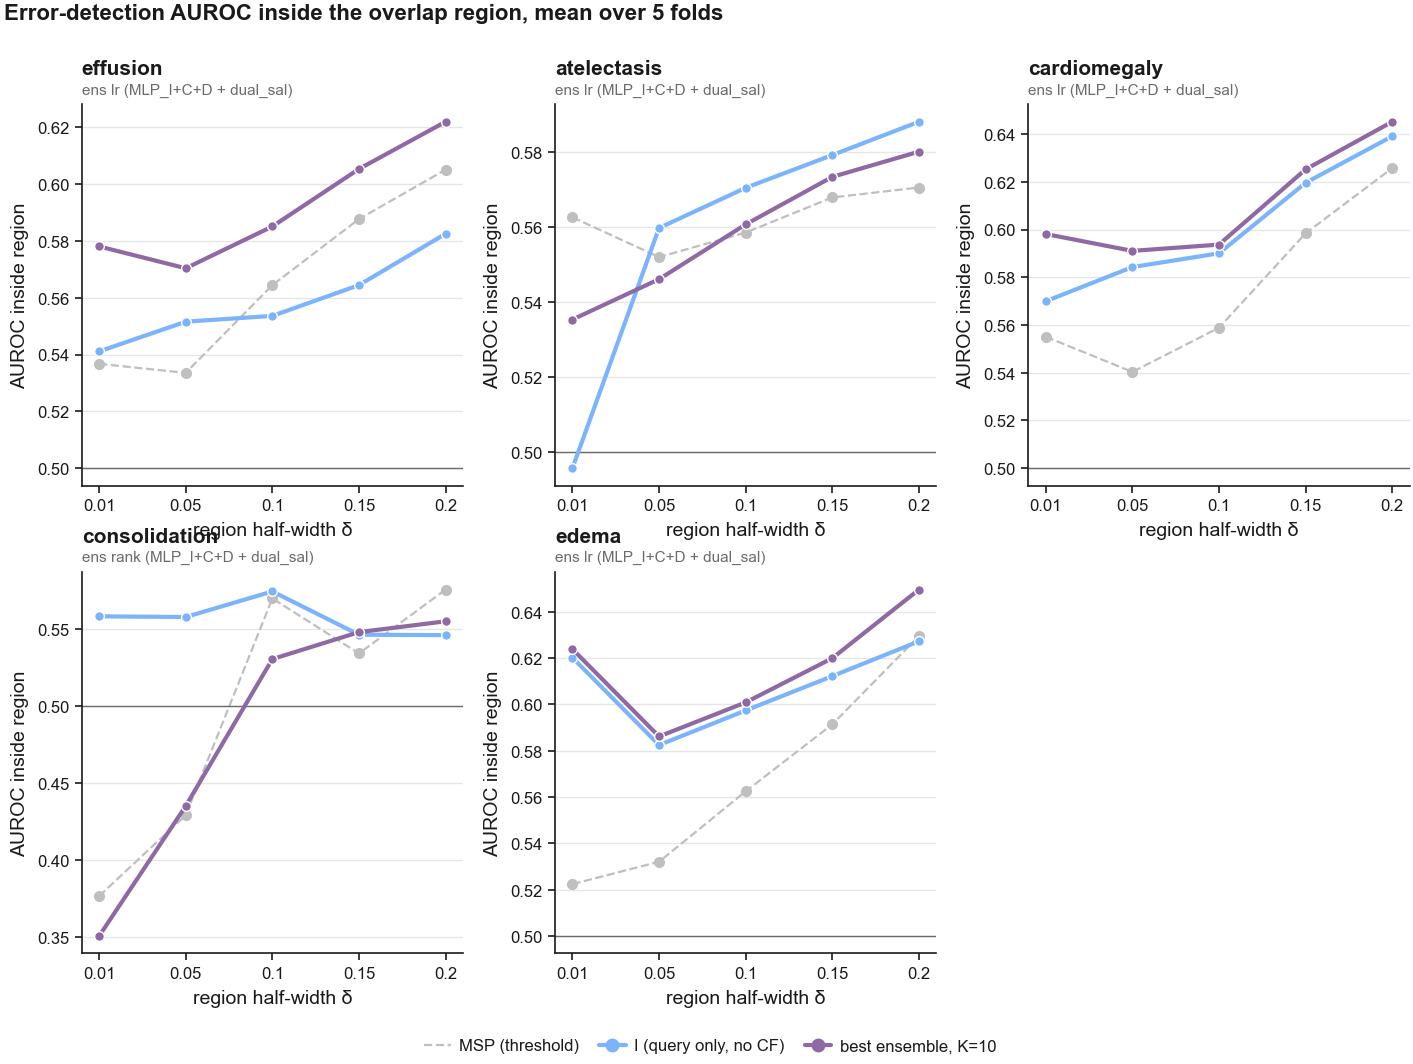

In [67]:
def overlap_sweep_panel(ax, disease):
    o = OVERLAP[disease]
    x = np.arange(len(DELTAS))
    for m in MODELS:
        y = [np.nanmean(o["auc"][m, d]) if np.isfinite(o["auc"][m, d]).any() else np.nan for d in DELTAS]
        if m == "MSP":
            ax.plot(x, y, color=GREY, ls="--", lw=LW["ref"], marker="o", ms=3, zorder=2)
        else:
            ax.plot(x, y, color=OV_COLOR[m], lw=LW["line"], marker="o", ms=3.5,
                    mec="white", mew=0.5, zorder=3)
    ax.axhline(0.5, color=MUTED, lw=LW["hair"])
    ax.set_xticks(x); ax.set_xticklabels([f"{d:g}" for d in DELTAS])
    ax.set_xlabel("region half-width δ"); ax.set_ylabel("AUROC inside region")
    ax.grid(axis="y", zorder=0); ax.set_axisbelow(True)
    ax.set_box_aspect(1)
    ax.set_title(disease, pad=11)
    ax.text(0.0, 1.02, o["labels"]["ens"], transform=ax.transAxes,
            ha="left", va="bottom", fontsize=FS["tiny"], color=MUTED)


fig, axes = _grid(len(DISEASES), 3, panel=(FULL / 3, 66 * MM))
for ax, d in zip(axes, DISEASES):
    overlap_sweep_panel(ax, d)
fig.legend(handles=[msp_handle(f"MSP ({MSP_VARIANT})"),
                    line_handle(OV_COLOR["I"], "I (query only, no CF)"),
                    line_handle(OV_COLOR["ens"], f"best ensemble, K={K_MAIN}")],
           loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.02))
fig.suptitle("Error-detection AUROC inside the overlap region, mean over 5 folds",
             x=0.01, ha="left", y=1.0)
fig.tight_layout(rect=(0, 0.03, 1, 0.99))
save_fig(fig, "aim3b_overlap_auroc_sweep")
plt.show()

## 1c. The answer: ensemble gain inside the region, with 95% CIs

At δ = DELTA_MAIN. Left point: ens − MSP. Right point: ens − I. A gain is only a
counterfactual gain if the **ens − I** interval clears zero. Diseases with fewer than 200 C0
errors in the region are named but not drawn; their intervals are too wide to read (numbers in the table).

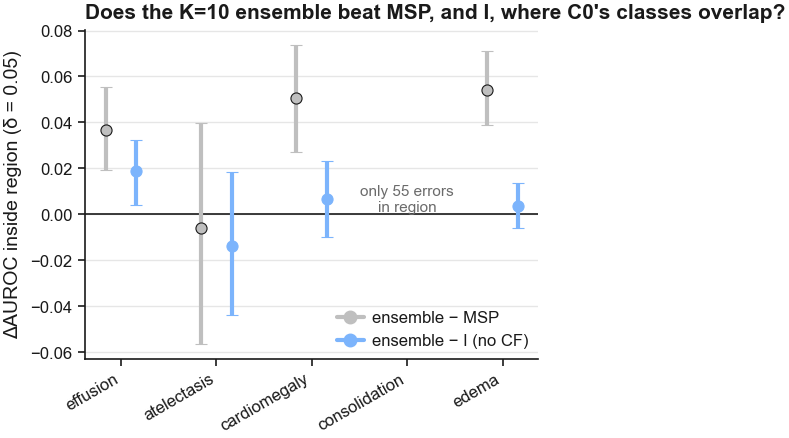

In [68]:
def gains(disease):
    """Point estimate and 95% CI of ens - MSP and ens - I at DELTA_MAIN."""
    o = OVERLAP[disease]
    point = {m: np.nanmean(o["auc"][m, DELTA_MAIN]) for m in MODELS}
    B = o["boot"]
    out = {}
    for ref in ("MSP", "I"):
        diff = B[:, MODELS.index("ens")] - B[:, MODELS.index(ref)]
        out[ref] = (point["ens"] - point[ref], *np.nanpercentile(diff, [2.5, 97.5]))
    return out


MIN_REGION_ERRORS = 200   # below this the interval spans the whole axis; the disease is named, not drawn


def region_errors(disease, delta=DELTA_MAIN):
    df = OVERLAP[disease]["df"]
    return int(((df.pc - 0.5).abs().values < delta)[df["correct"].values == 0].sum())


fig, ax = plt.subplots(figsize=(FULL * 0.4, 60 * MM))
w = 0.16
for i, d in enumerate(DISEASES):
    if (n := region_errors(d)) < MIN_REGION_ERRORS:
        ax.text(i, 0, f"only {n} errors\nin region", ha="center", va="bottom",
                fontsize=FS["tiny"], color=MUTED)
        continue
    g = gains(d)
    for dx, ref, c in ((-w, "MSP", GREY), (w, "I", OV_COLOR["I"])):
        est, lo, hi = g[ref]
        ax.errorbar(i + dx, est, yerr=[[est - lo], [hi - est]], fmt="o", ms=4, color=c,
                    mec=INK if ref == "MSP" else c, mew=0.4, capsize=2, lw=LW["line"], zorder=3)
ax.axhline(0, color=INK, lw=LW["axis"])
ax.set_xticks(range(len(DISEASES)), DISEASES, rotation=30, ha="right")
ax.set_ylabel(f"ΔAUROC inside region (δ = {DELTA_MAIN})")
ax.grid(axis="y", zorder=0); ax.set_axisbelow(True)
ax.legend(handles=[line_handle(GREY, "ensemble − MSP"), line_handle(OV_COLOR["I"], "ensemble − I (no CF)")],
          loc="lower right")
ax.set_title(f"Does the K={K_MAIN} ensemble beat MSP, and I, where C0's classes overlap?", loc="left")
fig.tight_layout()
save_fig(fig, "aim3b_overlap_gain")
plt.show()

In [69]:
def overlap_summary(delta=DELTA_MAIN):
    """One row per disease at `delta`.

    region / errors:   size of the region and the share of ALL C0 errors it holds
    AUROC *:           mean-fold AUROC inside the region
    ens-MSP, ens-I:    gain with 95% patient-bootstrap CI (only at DELTA_MAIN)
    ens>MSP folds:     in how many folds the ensemble wins
    ens-MSP all rows:  the same gain over every row, for contrast
    caught *:          flag as many region rows as there are errors; share that are real errors
    """
    rows = []
    for d in DISEASES:
        o = OVERLAP[d]; df = o["df"]
        inside = ((df.pc - 0.5).abs() < delta).values
        err = df["correct"].values == 0
        row = {"disease": d,
               "region": f"{inside.sum():,} ({inside.mean():.0%})",
               "errors": f"{err[inside].sum():,} ({err[inside].sum() / err.sum():.0%})"}
        for m in MODELS:
            row[f"AUROC {m}"] = round(np.nanmean(o["auc"][m, delta]), 4)
        if delta == DELTA_MAIN:
            for ref, (est, lo, hi) in gains(d).items():
                row[f"ens-{ref}"] = f"{est:+.4f} [{lo:+.4f}, {hi:+.4f}]"
        g = o["auc"]["ens", delta] - o["auc"]["MSP", delta]
        row["ens>MSP folds"] = f"{int((g > 0).sum())}/{int(np.isfinite(g).sum())}"
        row["ens-MSP all rows"] = round(np.mean(o["auc"]["ens", None] - o["auc"]["MSP", None]), 4)
        for m in MODELS:
            n_err, hit = errors_caught_in(df, o["scores"][m], inside)
            row[f"caught {m}"] = f"{hit / n_err:.0%}" if n_err else "-"
        rows.append(row)
    return pd.DataFrame(rows).set_index("disease")

overlap_summary()

,region,errors,AUROC MSP,AUROC I,AUROC ens,ens-MSP,ens-I,ens>MSP folds,ens-MSP all rows,caught MSP,caught I,caught ens
disease,,,,,,,,,,,,
effusion,"6,015 (7%)","2,935 (16%)",0.5336,0.5516,0.5704,"+0.0368 [+0.0194, +0.0553]","+0.0188 [+0.0041, +0.0322]",5/5,0.0057,52%,52%,54%
atelectasis,"1,155 (1%)",581 (2%),0.5519,0.5597,0.5461,"-0.0059 [-0.0563, +0.0399]","-0.0137 [-0.0437, +0.0185]",1/5,-0.0007,55%,54%,54%
cardiomegaly,"3,240 (4%)","1,659 (9%)",0.5404,0.5843,0.5911,"+0.0507 [+0.0272, +0.0739]","+0.0068 [-0.0100, +0.0233]",5/5,0.0038,55%,57%,58%
consolidation,115 (0%),55 (0%),0.4292,0.5580,0.4352,"+0.0060 [-0.1997, +0.2558]","-0.1228 [-0.2696, +0.1035]",1/2,-0.0007,40%,55%,51%
edema,"7,148 (8%)","3,647 (16%)",0.5321,0.5824,0.5861,"+0.0541 [+0.0387, +0.0711]","+0.0037 [-0.0061, +0.0139]",5/5,0.0069,54%,57%,57%


## 1d. Risk-coverage inside the region

The deployment view of 1b/1c, restricted to the region at δ = DELTA_MAIN. Within each fold, the
region's rows are ranked by a model's confidence and the least confident are rejected first.
risk(c) is C0's error rate among the share c of **region** rows that are kept. Curves are computed
per fold and averaged at the same coverages, because scores are only comparable within a fold.

Every curve ends at the same point (c = 1, all region rows kept, risk ≈ 0.5), since the region is
defined by C0 being right about half the time there. A model that ranks correctness better than
chance bends its curve **down** to the left of that point. The dotted line is the oracle (all correct
rows kept before any error); the flat line is random rejection.

**AURC** = mean risk over the curve, per fold, then averaged (lower is better). ΔAURC is reported as
reference − ens, so **positive means the ensemble rejects the region's errors better**. The CIs use the
same paired patient bootstrap as 1c.

In [ ]:
COV_GRID = np.linspace(0.1, 1.0, 91)   # coverages the per-fold curves are read at; < 0.1 is a handful of rows


def region_risk_curve(df, s, mask, grid=COV_GRID):
    """Mean-over-folds risk at each coverage in `grid`, on the rows in `mask` only.
    risk(c) = C0 error rate among the ceil(c * n) region rows of the fold with the highest `s`.
    Folds whose region has < MIN_CLASS correct or wrong rows are skipped, as in region_auc."""
    y, fold = df["correct"].values, df["fold"].values
    curves = []
    for f in np.unique(fold):
        m = mask & (fold == f)
        yf = y[m]
        if min(yf.sum(), len(yf) - yf.sum()) < MIN_CLASS:
            continue
        yf = yf[np.argsort(-s[m], kind="stable")]
        n_keep = np.ceil(grid * len(yf)).astype(int)
        curves.append(np.cumsum(1 - yf)[n_keep - 1] / n_keep)
    return np.mean(curves, axis=0) if curves else np.full(len(grid), np.nan)


def region_aurc(y, s):
    """AURC of one fold's region rows; NaN under the same MIN_CLASS rule as fast_auc."""
    y = np.asarray(y, int)
    if min(y.sum(), len(y) - y.sum()) < MIN_CLASS:
        return np.nan
    return aurc(y, s)


def boot_region_aurc(df, scores, mask, n_boot=N_BOOT, seed=0):
    """(n_boot, len(MODELS)) mean-fold region AURCs on patient-bootstrap draws.
    Same resampling as boot_region_auc (patients within folds, all models on the same draw)."""
    rng = np.random.default_rng(seed)
    y, fold, pid = df["correct"].values, df["fold"].values, df["patient_id"].values
    S = np.column_stack([scores[m] for m in MODELS])
    folds = []
    for f in np.unique(fold):
        idx = np.flatnonzero(mask & (fold == f))
        codes, uniq = pd.factorize(pid[idx])
        idx = idx[np.argsort(codes, kind="stable")]
        lens = np.bincount(codes, minlength=len(uniq))
        folds.append((idx, np.concatenate([[0], np.cumsum(lens)[:-1]]), lens))
    out = np.empty((n_boot, len(MODELS)))
    for b in range(n_boot):
        per_fold = []
        for idx, starts, lens in folds:
            g = rng.integers(len(lens), size=len(lens))
            L = lens[g]
            offs = np.arange(L.sum()) - np.repeat(np.cumsum(L) - L, L)
            i = idx[np.repeat(starts[g], L) + offs]
            per_fold.append([region_aurc(y[i], S[i, j]) for j in range(len(MODELS))])
        out[b] = np.nanmean(np.array(per_fold, float), axis=0)
    return out


def build_region_rc(disease, delta=DELTA_MAIN):
    o = OVERLAP[disease]; df = o["df"]
    mask = (df.pc - 0.5).abs().values < delta
    y, fold = df["correct"].values, df["fold"].values
    point = {m: np.nanmean([region_aurc(y[mask & (fold == f)], o["scores"][m][mask & (fold == f)])
                            for f in np.unique(fold)]) for m in MODELS}
    oracle = region_risk_curve(df, y.astype(float), mask)
    return {"mask": mask,
            "curves": {m: region_risk_curve(df, o["scores"][m], mask) for m in MODELS},
            "oracle": oracle,
            "base":   oracle[-1],        # mean-fold error rate, so it meets the curves at c = 1
            "aurc":   point,
            "boot":   boot_region_aurc(df, o["scores"], mask)}


REGION_RC = {d: build_region_rc(d) for d in DISEASES}

In [ ]:
def region_rc_panel(ax, disease):
    r = REGION_RC[disease]
    ax.set_title(disease, pad=11)
    ax.set_xlabel("coverage within region"); ax.set_ylabel("risk (C0 error rate)")
    ax.set_box_aspect(1)
    if (n := region_errors(disease)) < MIN_REGION_ERRORS:
        ax.text(0.5, 0.5, f"only {n} errors in region", transform=ax.transAxes,
                ha="center", va="center", fontsize=FS["small"], color=MUTED)
        ax.set_xticks([]); ax.set_yticks([])
        return
    ax.plot(COV_GRID, r["oracle"], color=MUTED, ls=":", lw=LW["ref"], zorder=1)
    ax.axhline(r["base"], color=MUTED, lw=LW["hair"], zorder=1)
    for m in MODELS:
        if m == "MSP":
            ax.plot(COV_GRID, r["curves"][m], color=GREY, ls="--", lw=LW["ref"], zorder=2)
        else:
            ax.plot(COV_GRID, r["curves"][m], color=OV_COLOR[m], lw=LW["line"], zorder=3)
    # Zoom on the model curves; the oracle drops to 0 and would flatten everything else.
    lo = min(np.nanmin(r["curves"][m]) for m in MODELS)
    ax.set_ylim(lo - 0.03, r["base"] + 0.03)
    ax.set_xlim(COV_GRID[0], 1)
    ax.grid(zorder=0); ax.set_axisbelow(True)
    a = r["aurc"]
    ax.text(0.0, 1.02, f"AURC  MSP {a['MSP']:.3f} · I {a['I']:.3f} · ens {a['ens']:.3f}",
            transform=ax.transAxes, ha="left", va="bottom", fontsize=FS["tiny"], color=MUTED)


fig, axes = _grid(len(DISEASES), 3, panel=(FULL / 3, 66 * MM))
for ax, d in zip(axes, DISEASES):
    region_rc_panel(ax, d)
fig.legend(handles=[msp_handle(f"MSP ({MSP_VARIANT})"),
                    line_handle(OV_COLOR["I"], "I (query only, no CF)"),
                    line_handle(OV_COLOR["ens"], f"best ensemble, K={K_MAIN}"),
                    Line2D([], [], color=MUTED, ls=":", lw=LW["ref"], label="oracle"),
                    Line2D([], [], color=MUTED, lw=LW["hair"], label="random rejection")],
           loc="lower center", ncol=5, bbox_to_anchor=(0.5, -0.02))
fig.suptitle(f"Risk-coverage inside the overlap region (δ = {DELTA_MAIN}), mean over 5 folds",
             x=0.01, ha="left", y=1.0)
fig.tight_layout(rect=(0, 0.03, 1, 0.99))
save_fig(fig, "aim3b_overlap_risk_coverage")
plt.show()


def region_rc_summary():
    """One row per disease at DELTA_MAIN: region AURC per model, and reference - ens with a
    95% patient-bootstrap CI (positive = ensemble better), plus risk at 50% region coverage."""
    rows = []
    i50 = int(np.argmin(np.abs(COV_GRID - 0.5)))
    for d in DISEASES:
        r = REGION_RC[d]; B = r["boot"]
        row = {"disease": d, "region errors": region_errors(d), "risk @100%": round(r["base"], 4)}
        for m in MODELS:
            row[f"AURC {m}"] = round(r["aurc"][m], 4)
        for ref in ("MSP", "I"):
            diff = B[:, MODELS.index(ref)] - B[:, MODELS.index("ens")]
            lo, hi = np.nanpercentile(diff, [2.5, 97.5])
            row[f"{ref}-ens"] = f"{r['aurc'][ref] - r['aurc']['ens']:+.4f} [{lo:+.4f}, {hi:+.4f}]"
        for m in MODELS:
            row[f"risk@50% {m}"] = round(r["curves"][m][i50], 4)
        rows.append(row)
    return pd.DataFrame(rows).set_index("disease")

region_rc_summary()

# Appendix

Older views, kept because the thesis figures still use them. They use the final system of
`C2_evaluation.ipynb`'s Aim 2 (`FINAL`: `I+C+D` and `dual_sal` at K=10, probability-free), the
same models 2a draws.

## A - Risk-coverage

The deployment view: reject the least-confident share and see what happens to the residual error
rate. This answers *"is C2 useful?"* without conditioning on C0's probability.

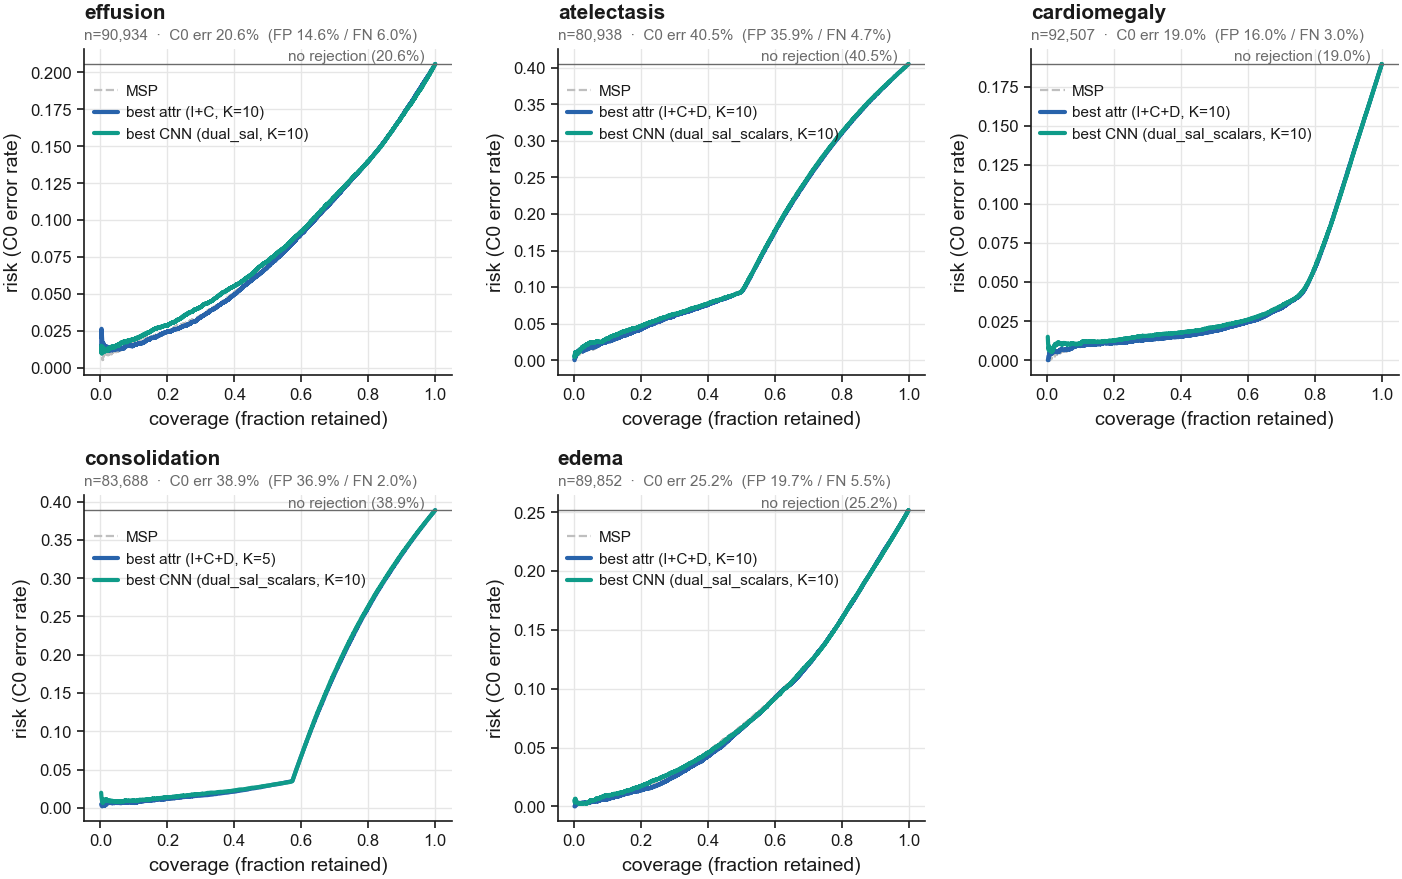

In [70]:
def risk_coverage_plot(disease, model="MLP", ks=None, ax=None):
    """MSP against the best model in each family -- no config is singled out by name.
    The winner is the joint (config, K) argmax of mean fold AUROC, the same one 2a
    draws, so the two figures always describe the same models."""
    ref = load_attributes(disease, FINAL["k"])
    if ref is None:
        print(f"{disease}: no attribute predictions yet"); return
    ax = ax or plt.subplots(figsize=(HALF, 70 * MM))[1]

    cov, risk = risk_coverage(ref["correct"], msp(ref, disease))
    ax.plot(cov, risk, color=GREY, ls="--", lw=LW["ref"], label="MSP")

    a = best_attr(disease, model, ks)
    if a:
        cfg, k, score, adf, _ = a
        cov, risk = risk_coverage(adf["correct"], score)
        ax.plot(cov, risk, color=BLUE, label=f"best attr ({cfg}, K={k})")

    c = best_cnn(disease, ks)
    if c:
        key, k, cnn, col, _ = c
        m = ref.merge(cnn[["path", col]], on="path", how="inner")
        cov, risk = risk_coverage(m["correct"], m[col])
        ax.plot(cov, risk, color=RED, label=f"best CNN ({key}, K={k})")

    base = 1 - ref["correct"].mean()
    ax.axhline(base, color=MUTED, lw=LW["hair"])
    ax.text(0.98, base, f"no rejection ({base:.1%}) ", fontsize=FS["tiny"], color=MUTED,
            va="bottom", ha="right")          # right-aligned: the legend owns the top-left
    ax.set_xlabel("coverage (fraction retained)"); ax.set_ylabel("risk (C0 error rate)")
    titled(ax, disease, ref)
    ax.grid(zorder=0); ax.set_axisbelow(True)
    ax.legend(loc="upper left", bbox_to_anchor=(0.0, 0.92), fontsize=FS["tiny"])
    return ax

fig, axes = _grid(len(DISEASES), 3, panel=(FULL / 3, 58 * MM))
for ax, d in zip(axes, DISEASES):
    risk_coverage_plot(d, ax=ax)
fig.tight_layout()
save_fig(fig, "aim2b_risk_coverage")

In [ ]:
def excess_risk_coverage(correct, score, min_n=200):
    """risk(c) - oracle risk(c) at every coverage. The oracle retains all correct samples
    before any error, so this is the per-coverage residual that E-AURC averages. Its mean
    over the untrimmed curve (min_n=1) equals e_aurc(correct, score)."""
    cov, risk = risk_coverage(correct, score, min_n)
    _, opt = risk_coverage(correct, np.asarray(correct, float), min_n)
    return cov, risk - opt

def e_aurc_plot(disease, model="MLP", ks=None, ax=None):
    """Same MSP / best attr / best CNN as risk_coverage_plot, on the excess-risk scale."""
    ref = load_attributes(disease, FINAL["k"])
    if ref is None:
        print(f"{disease}: no attribute predictions yet"); return
    ax = ax or plt.subplots(figsize=(HALF, 70 * MM))[1]

    m = msp(ref, disease)
    cov, ex = excess_risk_coverage(ref["correct"], m)
    ax.plot(cov, ex, color=GREY, ls="--", lw=LW["ref"],
            label=f"MSP (E-AURC {e_aurc(ref['correct'], m):.4f})")

    a = best_attr(disease, model, ks)
    if a:
        cfg, k, score, adf, _ = a
        cov, ex = excess_risk_coverage(adf["correct"], score)
        ax.plot(cov, ex, color=BLUE,
                label=f"best attr ({cfg}, K={k}) {e_aurc(adf['correct'], score):.4f}")

    c = best_cnn(disease, ks)
    if c:
        key, k, cnn, col, _ = c
        mm = ref.merge(cnn[["path", col]], on="path", how="inner")
        cov, ex = excess_risk_coverage(mm["correct"], mm[col])
        ax.plot(cov, ex, color=RED,
                label=f"best CNN ({key}, K={k}) {e_aurc(mm['correct'], mm[col]):.4f}")

    ax.axhline(0, color=MUTED, lw=LW["hair"])
    ax.text(0.02, 0, " perfect ranking", fontsize=FS["tiny"], color=MUTED,
            va="bottom", ha="left")
    ax.set_xlabel("coverage (fraction retained)"); ax.set_ylabel("excess risk (vs oracle)")
    titled(ax, disease, ref)
    ax.grid(zorder=0); ax.set_axisbelow(True)
    ax.legend(loc="upper left", fontsize=FS["tiny"])
    return ax

fig, axes = _grid(len(DISEASES), 3, panel=(FULL / 3, 58 * MM))
for ax, d in zip(axes, DISEASES):
    e_aurc_plot(d, ax=ax)
fig.tight_layout()
save_fig(fig, "aim2b_excess_risk_coverage")
